# 9 Living crystals

## Interacting active Brownian particles

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for sections 9.3 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

**Scientific reading.** Palacci et al., [*Living Crystals of Light-Activated Colloidal Surfers*](https://doi.org/10.1126/science.1230020), *Science* **339**, 936–940 (2013). Figures 9.4–9.6 in the textbook motivate the collision correction, phoretic drift and resulting structure.

We continue with **µm**, **s** units.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, "../09_modules")

<a id="volume-exclusion"></a>
## 9.3 Living crystals

The particles are identical *hard* disks of radius $R$, moving in 2D.

Two disks cannot overlap at any time.

For the dynamics, each time step we must make sure that any overlap is removed.

For this purpose, we use a *volume-exclusion* method (or *hard-sphere* correction):

For equal-radius disks of radius $R$, overlapping centers at separation $d<2R$ should be moved apart to separation $2R$, keeping their midpoint unchanged (textbook Figure 9.4, Exercise 9.3)



Let's see how the ***volume-exclusion* method** works in one example:

In [2]:
R = 1.0

# Particle 1
pos_1 = np.array([3.0, 4.0])
# Particle 2
pos_2 = np.array([4.2, 4.0])

pair = np.vstack((pos_1, pos_2))

midpoint_before = pair.mean(axis=0)
difference = pair[0] - pair[1]
distance = np.linalg.norm(difference)

print(
    f"Distance (initial): {distance:.3f} "
    f"({distance / (2 * R):.1f} diameters)"
)

if distance < 2 * R - 1e-6:
    print("Particles overlap.\n")

    pair_before = pair.copy()

    direction = difference / distance
    shift = 0.5 * (2 * R - distance) * direction

    pair[0] += shift
    pair[1] -= shift

    midpoint_after = pair.mean(axis=0)
    distance_after = np.linalg.norm(pair[0] - pair[1])

    print(
        f"Distance after: {distance_after:.3f} "
        f"({distance_after / (2 * R):.1f} diameters)"
    )

    print(
        "Particles overlap.\n"
        if distance_after < 2 * R - 1e-6
        else "Particles do not overlap.\n"
    )

    print(
        "Midpoint unchanged:",
        np.allclose(midpoint_after, midpoint_before)
    )

else:
    print("Particles do not overlap.\n")

Distance (initial): 1.200 (0.6 diameters)
Particles overlap.

Distance after: 2.000 (1.0 diameters)
Particles do not overlap.

Midpoint unchanged: True


Let's plot:

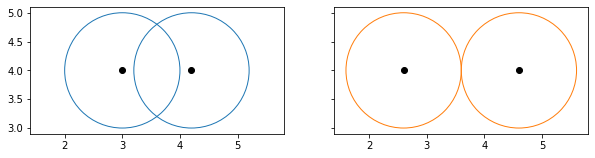

In [3]:
from matplotlib.patches import Circle

fig, axes = plt.subplots(
    1, 2, 
    figsize=(10, 5),
    sharex=True, 
    sharey=True
)

if distance < 2 * R - 1e-6:
    pairs = [pair_before, pair]
else:
    pairs = [pair]

for i, (ax, positions) in enumerate(zip(axes, pairs)):
    ax.plot(positions[:, 0], positions[:, 1], "ko")

    for x, y in positions:
        ax.add_patch(
            Circle((x, y), radius=R, fill=False, edgecolor=f"C{i}")
        )

    ax.set_aspect("equal")

plt.show()

To simulate **living crystals**, we have:
- many identical active Brownian particles with radius R
- a squared arena where they move
- periodic boundary conditions on the arena

<a id="periodic-boundary"></a>
Let's see **how we calculate the minimum distance** between two particles in the case of periodic boundary conditions.

This is important when calculating the proximity of particles in a periodic boundary condition setting.

We use the *minimum-image* displacement. 

In [4]:
L = 50.0

pos_1 = np.array([0.6, 20.0])
pos_2 = np.array([49.5, 20.0])

separation = pos_1 - pos_2
shortest_separation = (
    separation - L * np.rint(separation / L)
)
print(f"`Naive` distance: {np.linalg.norm(separation):.3f}")
print(f"Periodic distance: "
      f"{np.linalg.norm(shortest_separation):.3f}"
     )

`Naive` distance: 48.900
Periodic distance: 1.100


<a id="many-particles"></a>
Let's see how we initialize the position of the particles in the arena.

We need to reject new particles that are overlapping.

In [5]:
N = 12
L = 20.0
v = 2
R = 1.0
positions = np.empty((N, 2))
for i in range(N):
    while True:
        candidate = np.random.uniform(0, L, size=2)
        differences = positions[:i] - candidate
        differences -= L * np.rint(differences / L)
        if np.all(np.sum(differences**2, axis=1) >= (2 * R)**2):
            positions[i] = candidate
            break
phi0 = np.random.uniform(-np.pi, np.pi, N)

Let's plot the initial positions and orientations

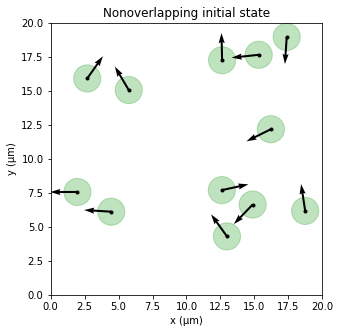

In [6]:
fig, ax = plt.subplots(figsize=(5, 5))

ax.plot(positions[:, 0], positions[:, 1], 'k.')

for x, y in positions:
    ax.add_patch(Circle((x, y), radius=R, 
               facecolor="C2", 
               edgecolor="C2",
               alpha=0.3
              ))
    
ax.quiver(
    positions[:, 0],
    positions[:, 1],
    v * np.cos(phi0),
    v * np.sin(phi0),
    color="black",
    angles="xy",
    scale_units="xy",
    scale=1
)


ax.set_xlim(0, L)
ax.set_ylim(0, L)
ax.set_aspect("equal")
ax.set_xlabel("x (µm)")
ax.set_ylabel("y (µm)")
ax.set_title("Nonoverlapping initial state")


plt.show()

Let's now implement the change in position and orientation each time step.

In [7]:
dt = 0.01
v = 3.0
D_T = 0.1
D_R = 1.0

pos = positions.copy()
phi = phi0.copy()

for i in range(N):
    u = np.array([np.cos(phi[i]), np.sin(phi[i])])
    pos[i] += (
        v * u * dt
        + np.sqrt(2 * D_T * dt) * np.random.normal(size=2)
    )
    phi[i] += np.sqrt(2 * D_R * dt) * np.random.normal()
pos %= L

We need to make sure there is no overlap.

We use the module's `correct_overlaps`.

In [8]:
import living_crystals as lc
pos = lc.correct_overlaps(pos, R, L)
differences = lc.minimum_image(
    pos[:, None, :] - pos[None, :, :], 
    L
)
distances = np.linalg.norm(differences, axis=-1)
np.fill_diagonal(distances, np.inf)
print(
    f"Minimum center-to-center distance: "
    f"{distances.min()/(2 * R):.3f} diameters."
)

Minimum center-to-center distance: 1.221 diameters.


<a id="phoretic"></a>
Let's see how *phoretic attraction* works.

For two disks separated by $r$, the **magnitude** of the additional **inward drift speed** is

$$v_p(r)=v_0\frac{R^2}{r^2},\quad r<r_c.$$

Here $v_0$ is an *interaction scale*, it is **not** the self-propulsion speed $v$. 

An attractive displacement of particle $i$ toward particle $j$ is **minus** the unit vector from $j$ to $i$ times $v_p(r)\,dt$. 

We use a finite cutoff $r_c$ (Figure 9.5).

Let's assume $r_c = 10 R$

In [9]:
rc = 10 * R

p1 = np.array([5.0, 5.0])
p2 = np.array([9.0, 5.0])
v0 = 10.0
rij = p1 - p2
r = np.linalg.norm(rij)

if r < rc - 1e-6:
    p_vel_1 = -v0 * R**2 * rij / r**3
    p_vel_2 = -p_vel_1
    print("Attraction velocities:", p_vel_1, p_vel_2)
else:
    print("Particles do not phoretically interact.")

Attraction velocities: [ 0.625 -0.   ] [-0.625  0.   ]


<a id="loop"></a>
Let's see how this works for a set of $N$ particles.

In [10]:
rc = 10 * R
phoretic_v = np.zeros_like(pos)
for i in range(N):
    for j in range(N):
        if i == j:
            continue
        separation = pos[i] - pos[j]
        separation -= L * np.rint(separation / L)
        r = np.linalg.norm(separation)
        if 0 < r < rc:
            phoretic_v[i] -= v0 * R**2 * separation / r**3

The module `living_crystals.py` uses broadcasting to form an $(N,N,2)$ array of pair displacements, and sums its last pair axis. This is faster for moderate $N$, but has the same signs, cutoff and $1/r^2$ drift magnitude as the visible loops above.

In [11]:
vectorized_ph_v = lc.phoretic_drift(pos, R, v0, rc, L)
print("Loop and vectorized versions agree:",
      np.allclose(phoretic_v, vectorized_ph_v))

Loop and vectorized versions agree: True


<a id="crystals"></a>
### Exercises 9.4–9.5

We reproduce the **qualitative** experiment of Figure 9.6 with $N=50$ particles in a $100$-µm box, choosing $v_0=0,20,50$ µm/s. 

In [12]:
N = 50
L = 100.0
R = 1.0
rc = 10 * R
initial = lc.initial_positions(N, L, R)
initial_angles = np.random.uniform(-np.pi, np.pi, N)

In [13]:
snapshots_pos = []
snapshots_phi = []
cluster_measurements = []
for attraction in [0.0, 20.0, 50.0]:
    particle_pos = initial.copy()
    particle_phi = initial_angles.copy()
    for step in range(500):
        particle_pos, particle_phi = lc.step_living(
            particle_pos, particle_phi, dt, v, D_T, D_R,
            R, attraction, rc, L)
    snapshots_pos.append(particle_pos)
    snapshots_phi.append(particle_phi)
    sizes = lc.cluster_sizes(particle_pos, R, L)
    cluster_measurements.append(sizes.max())

pygame 2.5.2 (SDL 2.28.3, Python 3.8.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


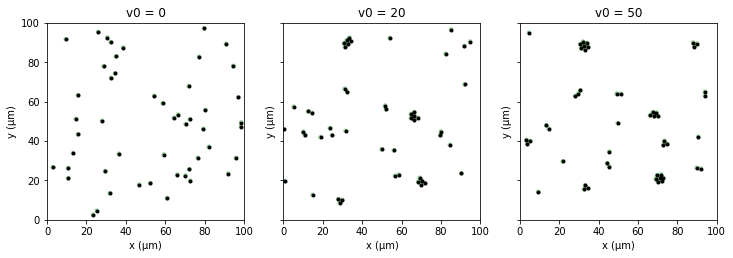

In [14]:
from lc_visualize import plot_particles

fig, axes = plt.subplots(
    1, 3, figsize=(12, 4),
    sharex=True, 
    sharey=True
)
for i, (attraction, pos, phi) in enumerate(
    zip([0, 20, 50], snapshots_pos, snapshots_phi)
):
    plot_particles(pos, phi, R, v, L, fig=fig, ax=axes[i])
    axes[i].set_xlabel("x (µm)")
    axes[i].set_ylabel("y (µm)")
    axes[i].set_title(f"v0 = {attraction}")
plt.show()


In [15]:
cluster_measurements

[2, 6, 7]

### Embedded pygame visualization

`lc_visualize.py` follows Chapter 1's working *offscreen pygame Surface → PNG bytes → `ipywidgets.Image`* approach. This avoids opening an unclosable window. The animation advances the **actual** `step_living` model and displays a subset of its steps. Install `pygame`, `ipywidgets`, `pillow` if missing.

In [16]:
import importlib.util
if all(
    importlib.util.find_spec(name) for name in [
        "pygame", "ipywidgets", "PIL"
    ]):
    from lc_visualize import animate_particles
    live_positions = lc.initial_positions(40, L, R)
    live_angles = np.random.uniform(-np.pi, np.pi, 40)
    
    def one_living_step(p, a):
        return lc.step_living(p, a, dt, v, D_T, D_R, R, 50.0, rc, L)
    live_positions, live_angles = animate_particles(
        live_positions, live_angles, one_living_step,
        frames=40, steps_per_frame=8, box_length=L, radius=R)
else:
    print("Animation optional: install pygame, ipywidgets and pillow, then rerun.")

<a id="questions"></a>
## Questions

[Q5: Volume-exclusion method](#q5)  
[Q6: Periodic geometry](#q6)  
[Q7: Many particles](#q7)  
[Q8: Phoretic attraction](#q8)  
[Q9: Loop and vectorization](#q9)  
[Q10: Living crystal](#q10)

Try answering before revisiting the code. The questions are deliberately left open.

<a id="q5"></a>
### Q5: Volume-exclusion method

Refer to [volume exclusion method](#volume-exclusion)

[Go back to questions](#questions)

Consider identical hard particles of radius $R=1\,\mu\mathrm{m}$, simulated using the volume-exclusion method implemented in the notebook and the module `living_crystals.py`.

**a)** Two particles have centers at $(4,5)$ and $(5,5)\,\mu\mathrm{m}$. Determine their corrected positions using the volume-exclusion method. Explain why the midpoint should remain unchanged.

**b)** Examine the function `correct_overlaps()` in the module `living_crystals.py`. How does the function determine whether two particles overlap, and how are their positions corrected?

**c)** Consider three particles arranged along a straight line. After correcting the overlap between the first two particles, the second particle overlaps with the third. Does this indicate a problem with the volume-exclusion algorithm? Explain how the module handles such situations.

<a id="q6"></a>
### Q6: Periodic geometry

Refer to [periodic geometry](#periodic-geometry)


[Go back to questions](#questions)

Consider particles moving in a square simulation box of side length $L=10\,\mu\mathrm{m}$ with periodic boundary conditions.

**a)** Two particles are located at $(1,5)$ and $(9,5)\,\mu\mathrm{m}$. What is their separation under periodic boundary conditions? Explain how the minimum-image convention determines this distance.

**b)** Two particles are located at $(1,5)$ and $(9,5)\,\mu\mathrm{m}$ and attract each other. In which direction should the particle at $(1,5)$ move due to this attraction? Explain.

**c)** The notebook calculates the minimum-image displacement using

$$
\Delta x_{\mathrm{min}}=\Delta x-L\,\mathrm{rint}\left(\frac{\Delta x}{L}\right).
$$

Explain the role of `np.rint` in this expression. What would go wrong if the ordinary coordinate difference were used instead?


<a id="q7"></a>
### Q7: Many particles

Refer to [many particle](#many-particles)

[Go back to questions](#questions)

Consider the simulation of active Brownian particles in Section 9.3, where particles move in a square box with periodic boundary conditions and interact through volume exclusion.

**a)** Examine the code used to initialize the positions of $N=12$ particles. How does the code ensure that no two particles overlap initially?

**b)** Examine the code that updates the positions and orientations of the particles. Which terms are responsible for self-propulsion, translational diffusion, and rotational diffusion?

**c)** After updating the particle positions, the notebook calls `correct_overlaps()` from the module `living_crystals.py`. Why is this correction necessary even though the particles were initially placed without overlaps?

<a id="q8"></a>
### Q8: Phoretic attraction

Refer to [phoretic attraction](#phoretic-attraction)

[Go back to questions](#questions)

Consider active Brownian particles of radius $R=1\,\mu\mathrm{m}$ interacting through the phoretic attraction described by Eq. (9.5):

$$
v_p(r)=v_0\frac{R^2}{r^2}.
$$

Assume $v_0=20\,\mu\mathrm{m/s}$ and an interaction cutoff $r_c=10R$.

**a)** Two particles are separated by $r=2\,\mu\mathrm{m}$. If their separation doubles, how does the phoretic drift speed change? Explain why this interaction can promote clustering.

**b)** Suppose the volume-exclusion correction is removed while the phoretic attraction is retained. What would happen when particles approach each other? Explain why the resulting configurations may be physically unrealistic.

**c)** Suppose the interaction cutoff is increased from $r_c=5R$ to $r_c=10R$, keeping all other parameters unchanged. Does this change the phoretic attraction between two particles already separated by $3R$? Could it nevertheless affect the collective behavior of the system? Explain.


<a id="q9"></a>
### Q9: Loop and vectorization

Refer to [loop and vectorization](#loop) and the module [living_crystals.py](../09_modules/living_crystals.py)


[Go back to questions](#questions)

The notebook calculates phoretic interactions between particles using explicit Python loops and NumPy vectorization.

**a)** The phoretic drift of a particle is calculated by summing the contributions from neighboring particles. Consider a particle with two identical neighbors at equal distances, one directly to its left and one directly to its right. What is its total phoretic drift due to these neighbors? Explain.

**b)** Suppose the number of particles is increased from $N=100$ to $N=1000$. Approximately how does the number of possible pairwise interactions change? Explain why this matters for the computational performance of the simulation.


<a id="q10"></a>
### Q10: Living crystals

Refer to [living crystals](#crystals) and the module [living_crystals.py](../09_modules/living_crystals.py)


[Go back to questions](#questions)

Consider the living-crystal simulations in the notebook, with $N=50$ active Brownian particles in a square box of side length $L=100\,\mu\mathrm{m}$. The simulations compare phoretic interaction strengths $v_0=0$, $20$, and $50\,\mu\mathrm{m/s}$.

**a)** Increasing the phoretic interaction strength $v_0$ generally produces larger clusters. Would these clusters remain permanently unchanged once formed? Explain why these structures are called living crystals.

**b)** Examine the living-crystal simulation results for $v_0=0$, $20$, and $50\,\mu\mathrm{m/s}$. How does the spatial distribution of particles change as the attraction strength increases? What differences do you observe in the formation of clusters?

**c)** Examine the function `step_living()` in the module `living_crystals.py`. Which terms contribute to the particle displacement during each time step? Why is `correct_overlaps()` called after updating the particle positions?